In [1]:
import csv
import math
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

plt.rcParams["figure.dpi"] = 140


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def tanh_act(x):
    return np.tanh(x)


def relu(x):
    return np.maximum(0.0, x)


def get_sampling_bounds(act_name):
    if act_name == "tanh":
        return -1.0, 1.0, -1.0, 1.0
    return 0.0, 1.0, 0.0, 1.0


def sample_input_points(act_name, n_samples=4000, seed=42):
    rng = np.random.default_rng(seed)
    x_low, x_high, y_low, y_high = get_sampling_bounds(act_name)
    single_edge_a = rng.uniform(x_low, x_high, size=n_samples).astype(np.float64)
    two_input_a = rng.uniform(x_low, x_high, size=n_samples).astype(np.float64)
    two_input_b = rng.uniform(x_low, x_high, size=n_samples).astype(np.float64)
    return {
        "single_edge_a": single_edge_a,
        "two_input_a": two_input_a,
        "two_input_b": two_input_b,
        "x_low": x_low,
        "x_high": x_high,
        "y_low": y_low,
        "y_high": y_high,
    }


def discretize_uniform(values, low, high, bins):
    scaled = (values - low) / (high - low)
    idx = np.floor(scaled * bins).astype(np.int64)
    np.clip(idx, 0, bins - 1, out=idx)
    return idx


def encode_states(codes, bins):
    if codes.ndim == 1:
        return codes.astype(np.int64)
    powers = (bins ** np.arange(codes.shape[1], dtype=np.int64)).reshape(1, -1)
    return (codes * powers).sum(axis=1, dtype=np.int64)


def causal_metrics_from_encoded_states(c_state, e_state, n_cause_states):
    n_samples = c_state.shape[0]
    c_u, c_inv = np.unique(c_state, return_inverse=True)
    e_u, e_inv = np.unique(e_state, return_inverse=True)

    pairs = np.stack([c_inv, e_inv], axis=1)
    pair_u, pair_counts = np.unique(pairs, axis=0, return_counts=True)

    pc = np.bincount(pair_u[:, 0], weights=pair_counts, minlength=c_u.shape[0]).astype(np.float64)
    pe = np.bincount(pair_u[:, 1], weights=pair_counts, minlength=e_u.shape[0]).astype(np.float64)

    pce = pair_counts.astype(np.float64) / n_samples
    pc = pc / n_samples
    pe = pe / n_samples

    eps = 1e-30
    log_pc = np.log2(pc[pair_u[:, 0]] + eps)
    log_pe = np.log2(pe[pair_u[:, 1]] + eps)
    log_pce = np.log2(pce + eps)

    h_e_bits = -np.sum(pe * np.log2(pe + eps))
    h_e_given_c_bits = -np.sum(pce * (log_pce - log_pc))
    ei_bits = np.sum(pce * (log_pce - log_pc - log_pe))

    max_cause_bits = math.log2(n_cause_states)
    determinism = 1.0 - (h_e_given_c_bits / max_cause_bits)
    degeneracy = 1.0 - (h_e_bits / max_cause_bits)
    specificity = 1.0 - degeneracy
    causal_power = determinism - degeneracy

    metrics = {
        "ei_bits": float(ei_bits),
        "h_e_bits": float(h_e_bits),
        "h_e_given_c_bits": float(h_e_given_c_bits),
        "determinism": float(determinism),
        "degeneracy": float(degeneracy),
        "specificity": float(specificity),
        "causal_power": float(causal_power),
    }
    for key, value in metrics.items():
        if abs(value) < 1e-12:
            metrics[key] = 0.0
    return metrics


def print_progress(prefix, current, total, last_percent, step_percent=5):
    percent = int((current * 100) / total)
    if percent >= last_percent + step_percent or current == total:
        print(f"[{prefix}] {percent:3d}% ({current}/{total})", flush=True)
        return percent
    return last_percent


def estimate_single_edge_curve(act_name, act_fn, bins_list, n_samples=30000, progress_prefix=None):
    rng = np.random.default_rng(42)
    weights = np.linspace(0.0, 27.0, 91)
    metric_names = [
        "ei_bits",
        "determinism",
        "degeneracy",
        "specificity",
        "causal_power",
        "h_e_bits",
        "h_e_given_c_bits",
    ]

    x_low, x_high, y_low, y_high = get_sampling_bounds(act_name)
    a = rng.uniform(x_low, x_high, size=n_samples).astype(np.float64)

    curves = {metric: {b: [] for b in bins_list} for metric in metric_names}
    rows = []
    total_steps = len(bins_list) * len(weights)
    step = 0
    last_percent = -1

    for b in bins_list:
        x_code = discretize_uniform(a, x_low, x_high, b)
        x_state = encode_states(x_code, b)
        n_cause_states = b
        for w in weights:
            z = w * a
            y = act_fn(z)
            y_code = discretize_uniform(y, y_low, y_high, b)
            metrics = causal_metrics_from_encoded_states(
                x_state,
                encode_states(y_code, b),
                n_cause_states=n_cause_states,
            )
            for metric in metric_names:
                curves[metric][b].append(metrics[metric])
            rows.append(
                {
                    "panel": f"single_{act_name}",
                    "bins": b,
                    "n_cause_states": n_cause_states,
                    "weight_a_to_b": float(w),
                    **metrics,
                }
            )
            step += 1
            if progress_prefix is not None:
                last_percent = print_progress(progress_prefix, step, total_steps, last_percent)

    return weights, curves, rows


def estimate_two_to_one_manifold(
    act_name,
    act_fn,
    bins_list=None,
    n_samples=100000,
    grid_size=41,
    progress_prefix=None,
):
    rng = np.random.default_rng(123)
    metric_names = [
        "ei_bits",
        "determinism",
        "degeneracy",
        "specificity",
        "causal_power",
        "h_e_bits",
        "h_e_given_c_bits",
    ]

    if bins_list is None:
        bins_list = [32]

    x_low, x_high, y_low, y_high = get_sampling_bounds(act_name)
    w_min, w_max = -9.0, 9.0

    w_vals = np.linspace(w_min, w_max, grid_size)

    a = rng.uniform(x_low, x_high, size=n_samples).astype(np.float64)
    b = rng.uniform(x_low, x_high, size=n_samples).astype(np.float64)
    rows = []
    manifolds = {metric: [] for metric in metric_names}
    total_steps = len(bins_list) * grid_size * grid_size
    step = 0
    last_percent = -1

    for bins in bins_list:
        x_codes = np.stack(
            [
                discretize_uniform(a, x_low, x_high, bins),
                discretize_uniform(b, x_low, x_high, bins),
            ],
            axis=1,
        )
        x_state = encode_states(x_codes, bins)
        n_cause_states = bins ** 2

        manifold = {metric: np.zeros((grid_size, grid_size), dtype=np.float64) for metric in metric_names}
        for i, w_ac in enumerate(w_vals):
            for j, w_bc in enumerate(w_vals):
                z = w_ac * a + w_bc * b
                c = act_fn(z)
                c_code = discretize_uniform(c, y_low, y_high, bins)
                metrics = causal_metrics_from_encoded_states(
                    x_state,
                    encode_states(c_code, bins),
                    n_cause_states=n_cause_states,
                )
                for metric in metric_names:
                    manifold[metric][j, i] = metrics[metric]
                rows.append(
                    {
                        "panel": f"two_to_one_{act_name}",
                        "bins": bins,
                        "n_cause_states": n_cause_states,
                        "weight_a_to_c": float(w_ac),
                        "weight_b_to_c": float(w_bc),
                        **metrics,
                    }
                )
                step += 1
                if progress_prefix is not None:
                    last_percent = print_progress(progress_prefix, step, total_steps, last_percent)
        for metric in metric_names:
            manifolds[metric].append(manifold[metric])

    fused_manifold = {
        metric: np.mean(np.stack(metric_manifolds, axis=0), axis=0)
        for metric, metric_manifolds in manifolds.items()
    }
    return w_vals, fused_manifold, rows


def nearest_weight_for_peak(weights, values):
    idx = int(np.argmax(values))
    return float(weights[idx]), float(values[idx])


def plot_metric_figure(out_png, curves_data, manifolds_data, metric_key, metric_label, add_reference_markers=False):
    fig = plt.figure(figsize=(16, 9))

    for col, (act_label, weights, curves) in enumerate(curves_data):
        ax = plt.subplot(2, 3, col + 1)
        for bins, vals in sorted(curves[metric_key].items()):
            ax.plot(weights, vals, linewidth=1.8, label=f"Bins={bins}")

        if add_reference_markers:
            if act_label == "Sigmoid":
                x_star = math.e
                note = "e"
            elif act_label == "Tanh":
                x_star = 1.0 / math.tanh(1.0)
                note = "coth(1)"
            else:
                x_star = 1.0
                note = "1"

            ref_curve = curves[metric_key][32] if 32 in curves[metric_key] else list(curves[metric_key].values())[0]
            y_star = np.interp(x_star, weights, ref_curve)
            ax.scatter([x_star], [y_star], s=44, color="black", zorder=6)
            ax.text(x_star, y_star, f"  {note}", fontsize=10, va="bottom")

        ax.set_title(f"({chr(ord('a') + col)}) {act_label}")
        ax.set_xlabel("A -> B Weight")
        ax.set_ylabel(metric_label)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    for col, (act_label, w_vals, manifolds) in enumerate(manifolds_data):
        ax = fig.add_subplot(2, 3, col + 4, projection="3d")
        manifold = manifolds[metric_key]
        w_bc_grid, w_ac_grid = np.meshgrid(w_vals, w_vals)
        surf = ax.plot_surface(
            w_bc_grid,
            w_ac_grid,
            manifold.T,
            cmap="viridis",
            linewidth=0,
            antialiased=True,
            rcount=manifold.shape[0],
            ccount=manifold.shape[1],
        )
        ax.set_title(f"({chr(ord('d') + col)}) {act_label}")
        ax.set_xlabel("B -> C Weight")
        ax.set_ylabel("A -> C Weight")
        ax.set_zlabel(metric_label)
        ax.view_init(elev=27, azim=-135)
        cb = fig.colorbar(surf, ax=ax, pad=0.08, shrink=0.65)
        cb.set_label(metric_label)

    fig.suptitle(f"Figure 1 Reproduction: {metric_label} as a Function of Weight and Connectivity", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(out_png, dpi=170)
    plt.close(fig)


def save_csv(rows, path):
    if not rows:
        return

    fieldnames = []
    seen = set()
    for row in rows:
        for key in row.keys():
            if key not in seen:
                seen.add(key)
                fieldnames.append(key)

    with path.open("w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fieldnames, extrasaction="ignore")
        w.writeheader()
        w.writerows(rows)


def run_full_experiment(
    out_root="results",
    bins_list=None,
    single_samples=30000,
    manifold_samples=100000,
    grid_size=41,
):
    start = time.time()
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    out_dir = Path(out_root) / f"figure1_reproduction_{ts}"
    out_dir.mkdir(parents=True, exist_ok=True)

    if bins_list is None:
        bins_list = [8, 16, 32, 64]

    single_specs = [
        ("Sigmoid", "sigmoid", sigmoid),
        ("Tanh", "tanh", tanh_act),
        ("ReLU", "relu", relu),
    ]

    curves_data = []
    all_rows = []
    peak_rows = []

    print("[Stage] Computing single-edge EI curves (a, b, c)", flush=True)
    for label, key, fn in single_specs:
        stage_start = time.time()
        print(f"[Start] Single-edge: {label}", flush=True)
        weights, curves, rows = estimate_single_edge_curve(
            act_name=key,
            act_fn=fn,
            bins_list=bins_list,
            n_samples=single_samples,
            progress_prefix=f"single-{key}",
        )
        curves_data.append((label, weights, curves))
        all_rows.extend(rows)

        for metric_key in ["ei_bits", "determinism", "degeneracy"]:
            for b, vals in curves[metric_key].items():
                w_peak, peak_value = nearest_weight_for_peak(weights, vals)
                peak_rows.append(
                    {
                        "activation": label,
                        "bins": b,
                        "metric": metric_key,
                        "peak_weight": w_peak,
                        "peak_value": peak_value,
                    }
                )
        print(f"[Done] Single-edge: {label} ({time.time() - stage_start:.1f}s)", flush=True)

    manifold_specs = [
        ("Sigmoid", "sigmoid", sigmoid),
        ("Tanh", "tanh", tanh_act),
        ("ReLU", "relu", relu),
    ]

    manifolds_data = []
    print("[Stage] Computing two-to-one EI manifolds (d, e, f)", flush=True)
    for label, key, fn in manifold_specs:
        stage_start = time.time()
        print(f"[Start] Two-to-one: {label}", flush=True)
        w_vals, manifold, rows = estimate_two_to_one_manifold(
            act_name=key,
            act_fn=fn,
            bins_list=bins_list,
            n_samples=manifold_samples,
            grid_size=grid_size,
            progress_prefix=f"manifold-{key}",
        )
        manifolds_data.append((label, w_vals, manifold))
        all_rows.extend(rows)
        print(f"[Done] Two-to-one: {label} ({time.time() - stage_start:.1f}s)", flush=True)

    out_png = out_dir / "figure1_reproduction.png"
    out_det_png = out_dir / "figure1_determinism.png"
    out_deg_png = out_dir / "figure1_degeneracy.png"
    out_csv = out_dir / "figure1_raw_metrics.csv"
    out_peak_csv = out_dir / "figure1_peak_summary.csv"

    plot_metric_figure(out_png, curves_data, manifolds_data, "ei_bits", "EI (bits)", add_reference_markers=True)
    plot_metric_figure(out_det_png, curves_data, manifolds_data, "determinism", "Determinism")
    plot_metric_figure(out_deg_png, curves_data, manifolds_data, "degeneracy", "Degeneracy")
    save_csv(all_rows, out_csv)
    save_csv(peak_rows, out_peak_csv)

    elapsed = time.time() - start
    print("[Stage] Finished figure rendering and CSV export", flush=True)
    print(f"Saved figure to: {out_png}")
    print(f"Saved figure to: {out_det_png}")
    print(f"Saved figure to: {out_deg_png}")
    print(f"Saved metrics to: {out_csv}")
    print(f"Saved peak summary to: {out_peak_csv}")
    print(f"Elapsed: {elapsed:.1f}s")

    return {
        "out_dir": out_dir,
        "figure_paths": [out_png, out_det_png, out_deg_png],
        "metrics_path": out_csv,
        "peak_summary_path": out_peak_csv,
        "curves_data": curves_data,
        "manifolds_data": manifolds_data,
    }


def main():
    return run_full_experiment()


print("Notebook helpers loaded. Run results = run_full_experiment() when you want to generate all figures.")

Notebook helpers loaded. Run results = run_full_experiment() when you want to generate all figures.


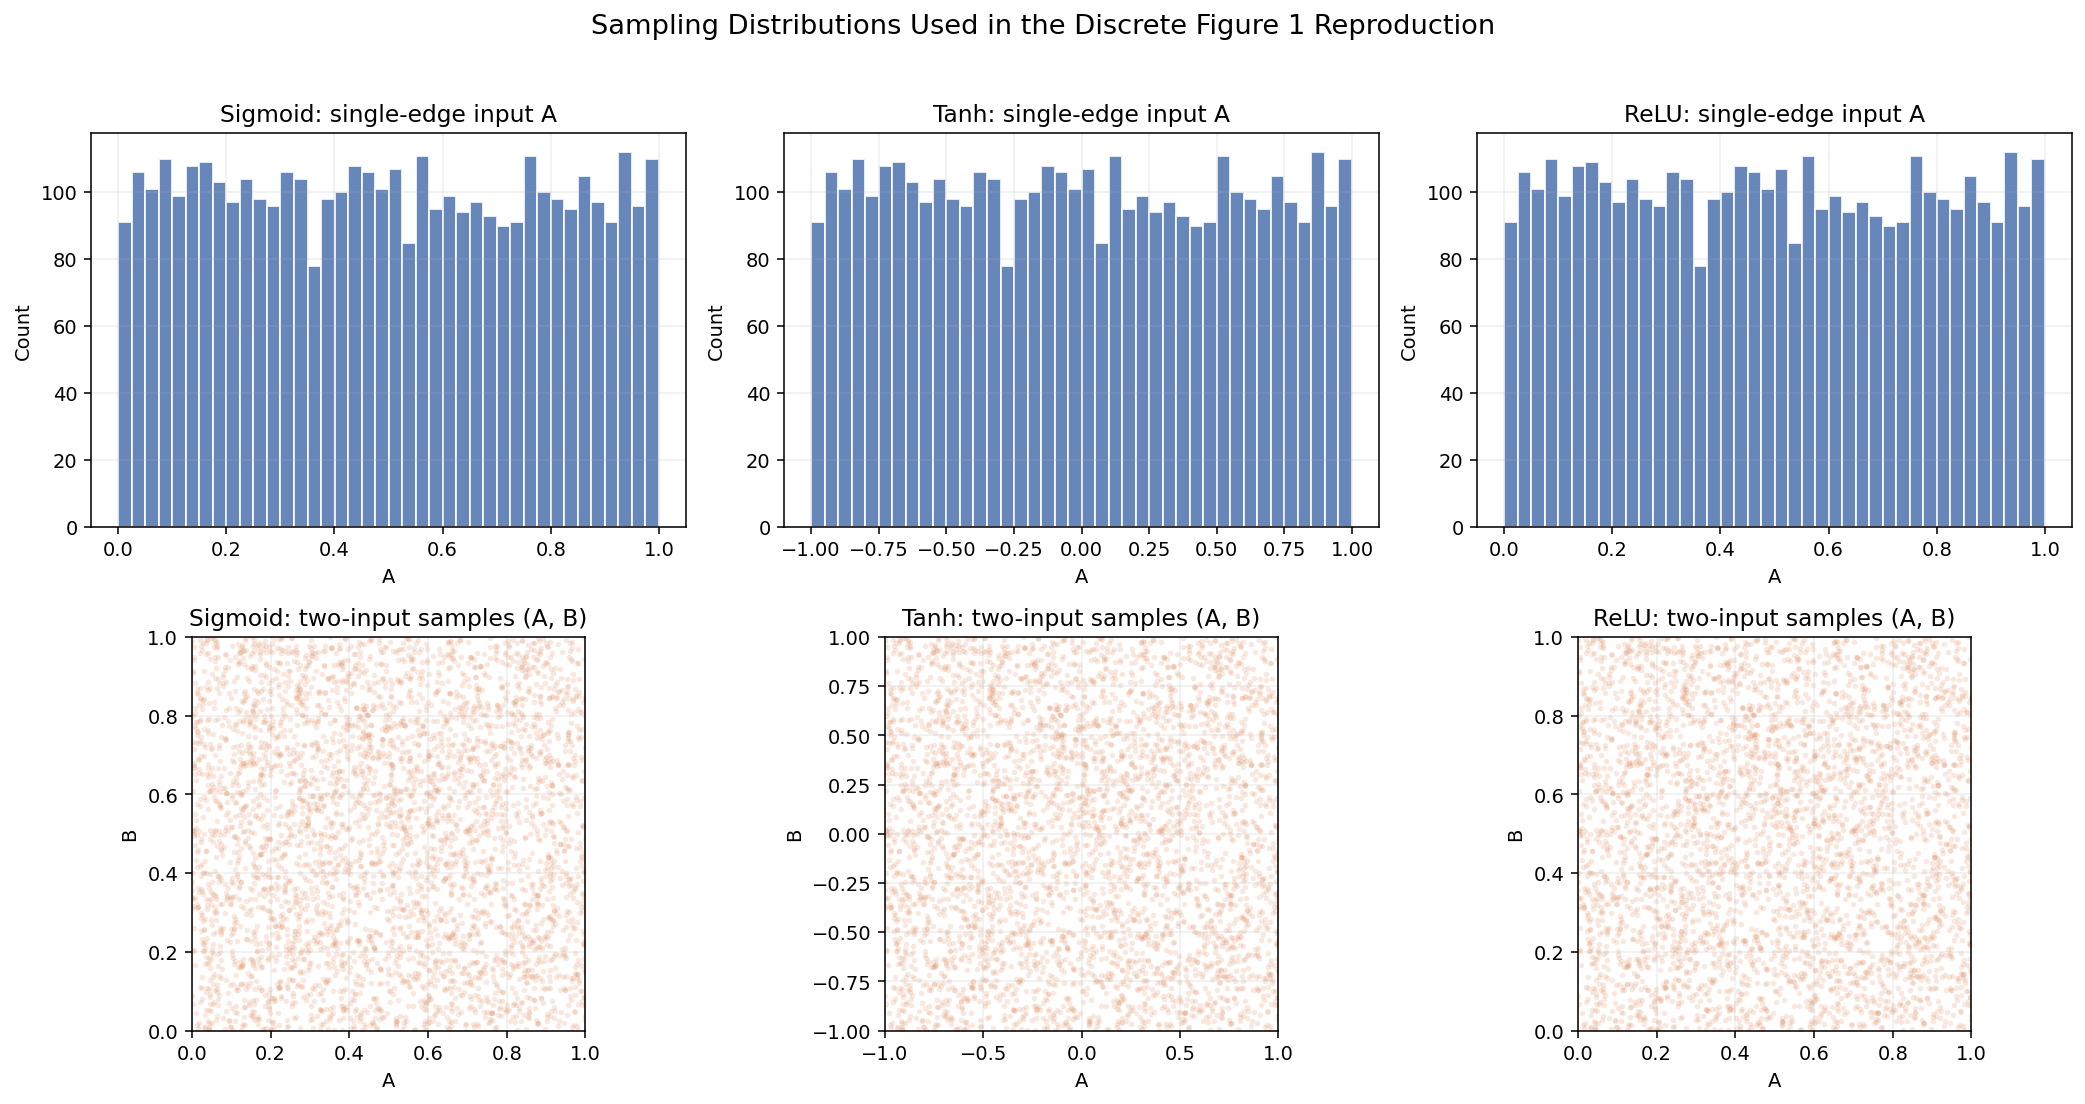

In [2]:
activation_specs = [
    ("Sigmoid", "sigmoid"),
    ("Tanh", "tanh"),
    ("ReLU", "relu"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (label, key) in enumerate(activation_specs):
    sampled = sample_input_points(key, n_samples=4000, seed=42)

    ax = axes[0, col]
    ax.hist(sampled["single_edge_a"], bins=40, color="#4C72B0", alpha=0.85, edgecolor="white")
    ax.set_title(f"{label}: single-edge input A")
    ax.set_xlabel("A")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)

    ax = axes[1, col]
    ax.scatter(
        sampled["two_input_a"],
        sampled["two_input_b"],
        s=8,
        alpha=0.18,
        color="#DD8452",
        linewidths=0,
    )
    ax.set_title(f"{label}: two-input samples (A, B)")
    ax.set_xlabel("A")
    ax.set_ylabel("B")
    ax.set_xlim(sampled["x_low"], sampled["x_high"])
    ax.set_ylim(sampled["x_low"], sampled["x_high"])
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

fig.suptitle("Sampling Distributions Used in the Discrete Figure 1 Reproduction", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()